# 03 - Plate layout: controls, edge effects, and why order matters

A policy hands you 96 compounds. Pipette them into the plate in the order the
policy returned them and you have introduced a bias that can be larger than
the effect you are measuring -- and that is *perfectly correlated with the
model's predictions*.

This notebook builds a real 96-well plate map, shows the confound, and shows
the fix.

## The biology

The outer ring of a microplate behaves differently from the interior:

- **Evaporation.** Edge wells have more exposed surface relative to volume and
  sit against the plate walls, so they lose solvent faster and their contents
  concentrate.
- **Temperature.** A stacked plate's interior equilibrates more slowly than its
  edges, so edge wells spend an incubation at a different temperature.
- **Gas exchange.** In cell-based assays, edge wells exchange gases differently
  and the cells grow differently.

The bias is typically 5-20% of signal and is systematic, so replicates in edge
wells do not average it away (Lundholt et al., 2003; Caraus et al., 2015).

In [1]:
import sys
from pathlib import Path

# Figures and tables land in results/ so the committed notebooks and the README
# reference the same files.
ROOT = Path.cwd()
if not (ROOT / "loopwise").exists():
    ROOT = ROOT.parent
FIGDIR = ROOT / "results" / "figures"
TABDIR = ROOT / "results" / "tables"
FIGDIR.mkdir(parents=True, exist_ok=True)
TABDIR.mkdir(parents=True, exist_ok=True)
print("loopwise", __import__("loopwise").__version__, "| figures ->", FIGDIR)

loopwise 0.1.0 | figures -> /home/user/loopwise/results/figures


In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from loopwise.plate import (
    PLATE_96,
    PLATE_384,
    PlateLayout,
    PlateTemplate,
    render_plate_map,
)

plt.rcParams.update({"figure.dpi": 110, "font.size": 9})
print(PLATE_96.describe())
print(PLATE_384.describe())

96-well (8x12 = 96 wells): 8 positive + 8 negative control wells, edge ring in use, 80 wells available for samples.
384-well (16x24 = 384 wells): 14 positive + 14 negative control wells, edge ring excluded, 280 wells available for samples.


## The template

The default 96-well layout reserves column 1 for negative (vehicle/DMSO)
controls and column 12 for positive controls. That is the bench convention, and
it has a useful side effect: both control columns are *themselves* on edges, so
the controls sample the edge effect and can be used to estimate it.

These wells are **reserved**: Loopwise will never place a sample in one. A
control silently overwritten by a sample gives you a plate you cannot
interpret and will not know you cannot interpret, so this is a hard invariant
with a test, not a convention.

In [3]:
print("positive controls:", PLATE_96.positive_control_wells)
print("negative controls:", PLATE_96.negative_control_wells)
print("reserved wells:", len(PLATE_96.reserved_wells))
print("available for samples:", PLATE_96.usable_wells)
print("\nedge wells among available sample wells:",
      sum(PLATE_96.is_edge(*PLATE_96.parse_well(w)) for w in PLATE_96.sample_wells),
      f"of {PLATE_96.usable_wells}")

positive controls: ('A12', 'B12', 'C12', 'D12', 'E12', 'F12', 'G12', 'H12')
negative controls: ('A1', 'B1', 'C1', 'D1', 'E1', 'F1', 'G1', 'H1')
reserved wells: 16
available for samples: 80

edge wells among available sample wells: 20 of 80


## A batch to lay out

80 compounds, with predicted scores running from 0.95 down to 0.02 -- i.e. a
batch in score order, which is what every selection policy returns.

In [4]:
n = 80
compound_ids = [f"CPD{i:03d}" for i in range(n)]
predicted = np.linspace(0.95, 0.02, n)
print(f"{n} compounds, predicted scores {predicted.max():.2f} down to {predicted.min():.2f}")

80 compounds, predicted scores 0.95 down to 0.02


## The naive layout, and the confound

`randomize=False` fills wells in reading order (A1, A2, ... H12) with compounds
in the order given. This is what a liquid handler does by default.

In [5]:
naive = PlateLayout.assign(
    compound_ids, template=PLATE_96, predicted_scores=predicted,
    seed=0, randomize=False, n_strata=4,
)
print(naive.summary())
print("\nscore stratum by well (3 = highest-scoring quarter):")
naive.to_grid(0, "score_stratum")

96-well (8x12 = 96 wells): 8 positive + 8 negative control wells, edge ring in use, 80 wells available for samples.
80 sample wells across 1 plate(s); controls intact: True.
Edge wells are 25% of available sample wells; highest-score stratum edge enrichment vs chance 2.0 (CHECK: uneven edge exposure, re-run with a different seed). With 80 samples in 4 strata this ratio is coarse -- one well either way moves it noticeably.

score stratum by well (3 = highest-scoring quarter):


,1,2,3,4,5,6,7,8,9,10,11,12
A,-1,3,3,3,3,3,3,3,3,3,3,-1
B,-1,3,3,3,3,3,3,3,3,3,3,-1
C,-1,2,2,2,2,2,2,2,2,2,2,-1
D,-1,2,2,2,2,2,2,2,2,2,2,-1
E,-1,1,1,1,1,1,1,1,1,1,1,-1
F,-1,1,1,1,1,1,1,1,1,1,1,-1
G,-1,0,0,0,0,0,0,0,0,0,0,-1
H,-1,0,0,0,0,0,0,0,0,0,0,-1


Every compound in the top-scoring quarter (stratum 3) is in rows A and B.
**Row A is an edge row.** The top stratum's edge enrichment is 2.0 -- twice
what chance would give -- so the highest predictions are systematically the
most edge-exposed wells on the plate.

If edge evaporation raises the signal, these compounds all read high, you
"confirm" the model, retrain on the confirmation, and chase an artifact. In an
active-learning loop that is worse than in a one-shot screen, because the
biased measurements become training data: the model learns the plate's
geometry.

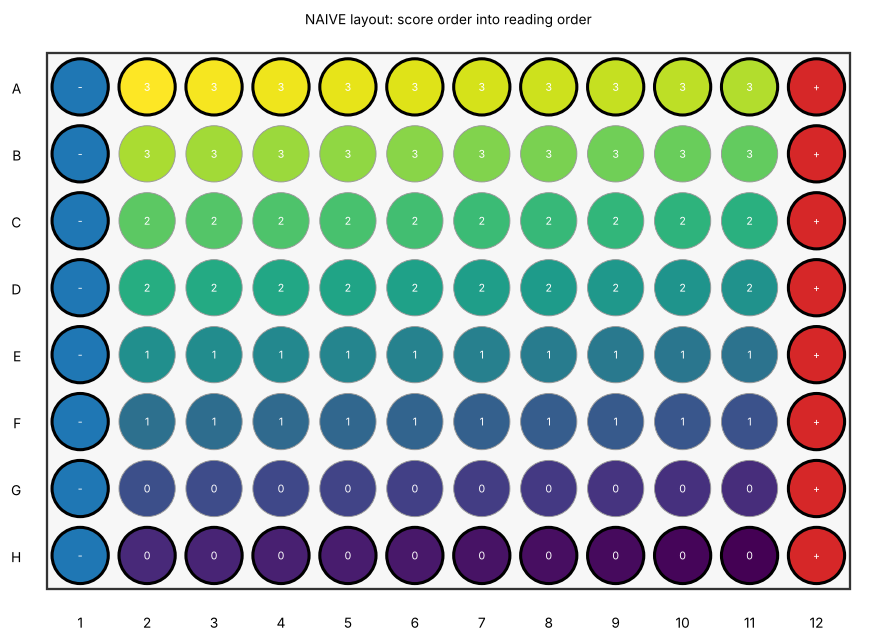

In [6]:
fig = render_plate_map(naive, title="NAIVE layout: score order into reading order")
FIGDIR.mkdir(parents=True, exist_ok=True)
fig.savefig(FIGDIR / "03_plate_naive_confounded.png", dpi=150, bbox_inches="tight")

## The stratified, randomized layout

The fix: bucket compounds by predicted score, then assign so each bucket is
spread across edge and interior wells and across all four quadrants *in
proportion to how many such wells exist*. Randomization within that constraint
keeps the assignment unbiased; the stratification stops chance from clustering
the predicted actives.

The obvious implementation is wrong, and the way it is wrong is instructive.
Dealing one compound per (plate, edge, quadrant) cell per turn -- plain
round-robin -- drains the small cells first: this plate has 20 edge sample
wells against 60 interior ones, so by the time the last stratum is dealt the
edge cells are empty and that stratum gets *no* edge wells. Still a
score/position correlation, just inverted. Loopwise instead spaces each cell's
wells evenly through a global sequence and does the same for the strata, so
zipping them balances both -- Bresenham's line algorithm, applied to wells.

In [7]:
layout = PlateLayout.assign(
    compound_ids, template=PLATE_96, predicted_scores=predicted, seed=7, n_strata=4,
)
print(layout.summary())
layout.to_grid(0, "score_stratum")

96-well (8x12 = 96 wells): 8 positive + 8 negative control wells, edge ring in use, 80 wells available for samples.
80 sample wells across 1 plate(s); controls intact: True.
Edge wells are 25% of available sample wells; highest-score stratum edge enrichment vs chance 1.0 (balanced). With 80 samples in 4 strata this ratio is coarse -- one well either way moves it noticeably.


,1,2,3,4,5,6,7,8,9,10,11,12
A,-1,0,1,2,3,0,2,3,1,3,0,-1
B,-1,0,1,3,2,0,3,2,3,1,2,-1
C,-1,0,0,3,1,1,0,2,1,1,0,-1
D,-1,0,3,1,3,0,0,1,3,1,2,-1
E,-1,3,1,2,3,2,2,1,0,2,2,-1
F,-1,1,3,3,2,0,2,2,1,2,3,-1
G,-1,0,1,2,3,1,1,3,0,2,3,-1
H,-1,3,0,3,0,1,0,0,2,1,2,-1


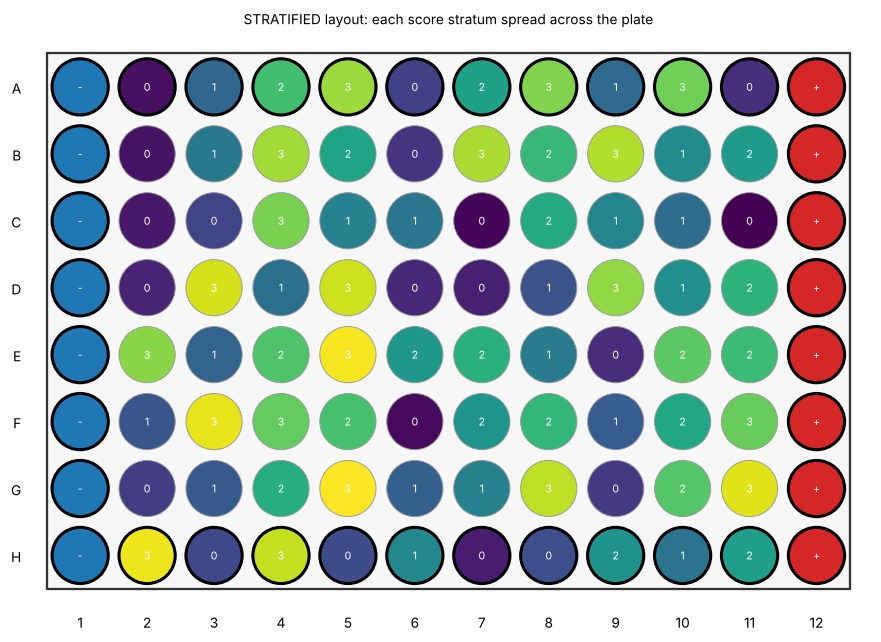

In [8]:
fig = render_plate_map(layout, title="STRATIFIED layout: each score stratum spread across the plate")
fig.savefig(FIGDIR / "03_plate_stratified.png", dpi=150, bbox_inches="tight")

In [9]:
rows = []
for seed in range(8):
    lay = PlateLayout.assign(compound_ids, template=PLATE_96,
                             predicted_scores=predicted, seed=seed)
    naive_lay = PlateLayout.assign(compound_ids, template=PLATE_96,
                                   predicted_scores=predicted, seed=seed, randomize=False)
    rows.append({
        "seed": seed,
        "stratified: top-stratum edge enrichment":
            lay.diagnostics["top_stratum_edge_enrichment"],
        "naive: top-stratum edge enrichment":
            naive_lay.diagnostics["top_stratum_edge_enrichment"],
    })
enrichment = pd.DataFrame(rows).set_index("seed")
print("1.0 = exactly what chance would give; 2.0 = twice as edge-exposed as it should be")
enrichment

1.0 = exactly what chance would give; 2.0 = twice as edge-exposed as it should be


,stratified: top-stratum edge enrichment,naive: top-stratum edge enrichment
seed,,
0,0.6,2.0
1,1.2,2.0
2,1.2,2.0
3,1.2,2.0
4,1.0,2.0
5,1.2,2.0
6,0.8,2.0
7,1.0,2.0


The stratified layout hovers around 1.0 across seeds; the naive layout is
pinned at 2.0 every time, because it is not random -- it is deterministic and
wrong.

The ratio is coarse: 20 edge wells across 4 strata means chance gives each
stratum 5 wells, so one well moves the ratio by 0.2. Read it as "not
systematically clustered", not "uniform to three decimals".

## Replicates

With `n_replicates=3`, 40 compounds need 120 wells -- two plates, since controls
leave 80 usable wells each. Replicates are placed in separate passes over the
global well sequence, so a compound's replicates land in different cells and
usually on different plates.

Why that matters: replicates sharing a position bias produce a reassuringly
tight standard deviation around a systematically wrong mean. That is worse than
no replicates, because it converts a known unknown into a false certainty.

In [10]:
triplicate = PlateLayout.assign(
    compound_ids[:40], template=PLATE_96,
    predicted_scores=predicted[:40], n_replicates=3, seed=3,
)
frame = triplicate.to_frame()
samples = frame[frame["content_type"] == "sample"]

print(f"{len(samples)} sample wells across {triplicate.n_plates} plates")
print(f"controls intact on every plate: {triplicate.control_wells_intact()}")
print("\nmean distinct plates per compound: "
      f"{samples.groupby('item_id')['plate'].nunique().mean():.2f} of 3 replicates")
print("mean distinct rows per compound:  "
      f"{samples.groupby('item_id')['row'].nunique().mean():.2f}")
samples[samples["item_id"] == "CPD000"][
    ["plate", "well", "row", "column", "replicate", "is_edge"]
]

120 sample wells across 2 plates
controls intact on every plate: True

mean distinct plates per compound: 1.80 of 3 replicates
mean distinct rows per compound:  2.67


,plate,well,row,column,replicate,is_edge
13,0,B2,B,2,2,False
115,1,B8,B,8,1,False
159,1,F4,F,4,3,False


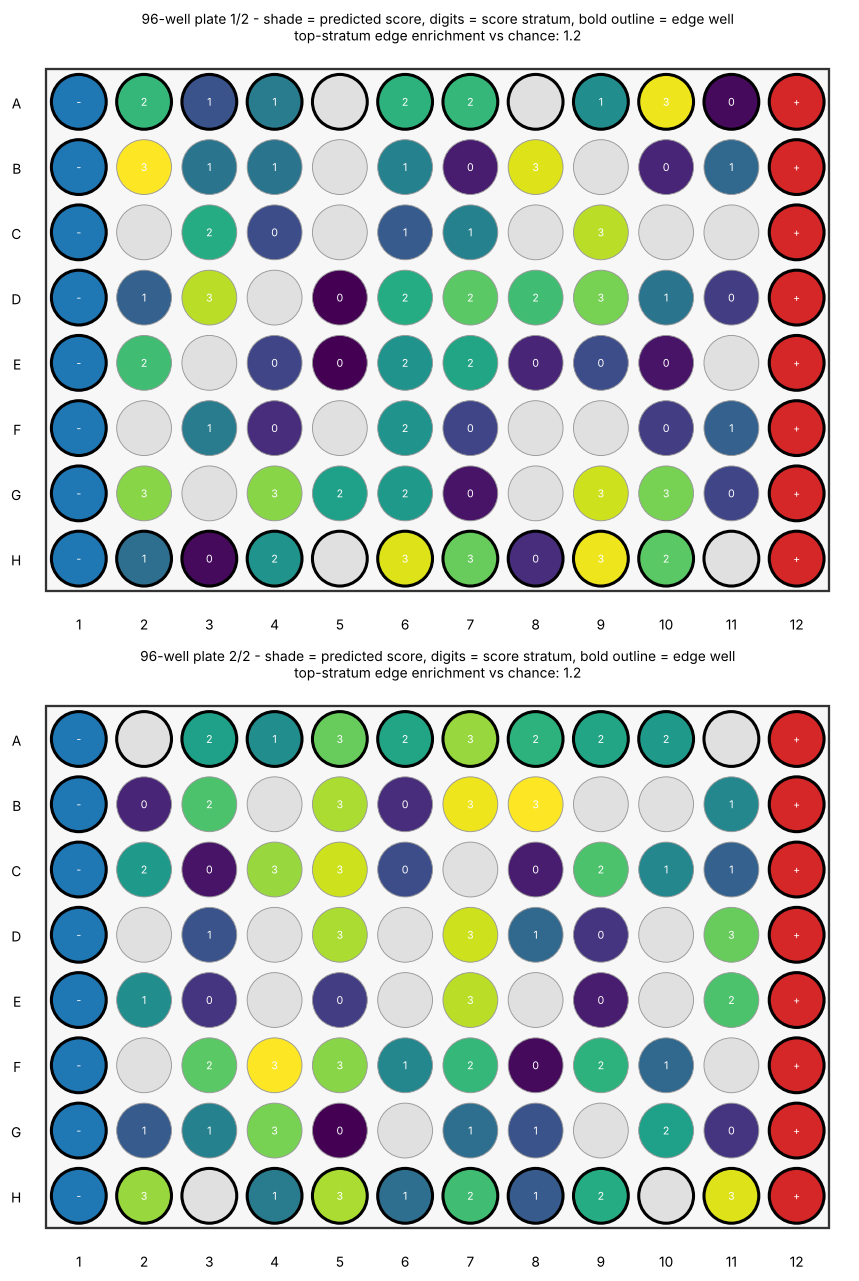

In [11]:
fig = render_plate_map(triplicate)
fig.savefig(FIGDIR / "03_plate_triplicate_two_plates.png", dpi=150, bbox_inches="tight")

## 384-well plates

`exclude_edge_wells` defaults to **True** on 384-well plates and False on
96-well. The ring is 20% of a 384-well plate against 36% of a 96, so
sacrificing it is far cheaper -- and 384-well edge effects are *worse*, because
smaller wells have a higher surface-to-volume ratio and evaporate
proportionally faster.

384-well (16x24 = 384 wells): 14 positive + 14 negative control wells, edge ring excluded, 280 wells available for samples.
280 sample wells across 1 plate(s); controls intact: True.
No sample wells sit on the edge ring (it is excluded), so edge effects cannot confound the samples at all.


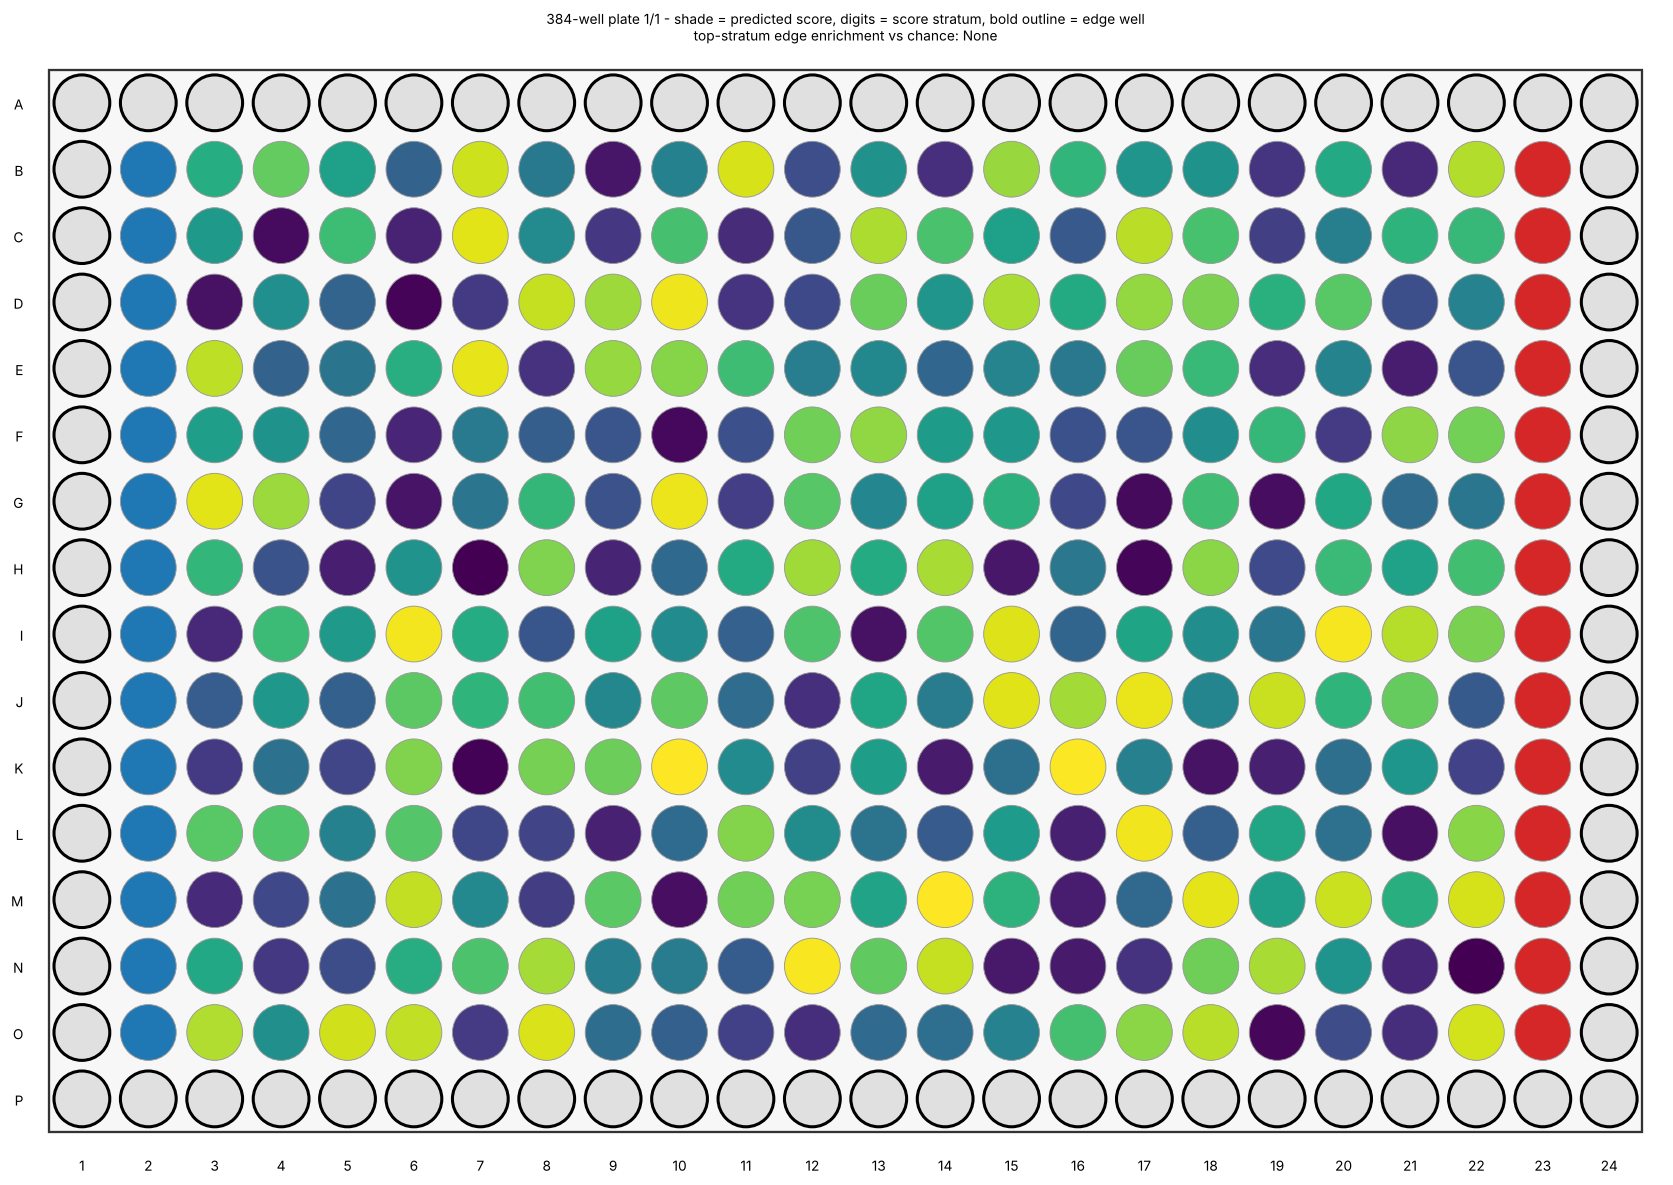

In [12]:
plate384 = PlateTemplate.plate384(exclude_edge_wells=True)
layout384 = PlateLayout.assign(
    [f"X{i:04d}" for i in range(280)], template=plate384,
    predicted_scores=np.linspace(0, 1, 280), seed=2,
)
print(layout384.summary())
fig = render_plate_map(layout384, annotate=False)
fig.savefig(FIGDIR / "03_plate_384_edge_excluded.png", dpi=150, bbox_inches="tight")

Every sample well is in the interior; the ring is empty. Edge effects cannot
confound the samples at all, at the cost of 76 wells.

## The output you hand the lab

A CSV, one row per well.

In [13]:
TABDIR.mkdir(parents=True, exist_ok=True)
path = layout.to_csv(str(TABDIR / "03_plate_map_96well.csv"))
written = pd.read_csv(path)
print(f"wrote {len(written)} wells to {path}")
written.head(14)

wrote 96 wells to /home/user/loopwise/results/tables/03_plate_map_96well.csv


,plate,well,row,column,content_type,item_id,replicate,predicted_score,score_stratum,is_edge
0,0,A1,A,1,negative_control,negative_control,1,NaN,-1,True
1,0,A2,A,2,sample,CPD076,1,0.055316,0,True
2,0,A3,A,3,sample,CPD053,1,0.326076,1,True
3,0,A4,A,4,sample,CPD024,1,0.667468,2,True
4,0,A5,A,5,sample,CPD012,1,0.808734,3,True
5,0,A6,A,6,sample,CPD064,1,0.196582,0,True
6,0,A7,A,7,sample,CPD034,1,0.549747,2,True
7,0,A8,A,8,sample,CPD015,1,0.773418,3,True
8,0,A9,A,9,sample,CPD052,1,0.337848,1,True
9,0,A10,A,10,sample,CPD017,1,0.749873,3,True


Columns: `plate, well, row, column, content_type, item_id, replicate,
predicted_score, score_stratum, is_edge`.

`is_edge`, `row` and `column` are there so that if you want to *correct* for
spatial bias rather than just avoid confounding it, you can fit a
plate-position model to your control wells afterwards.

## What this does not handle

- It does not model the edge effect, only avoid confounding it.
- It does not know your liquid handler; translating the CSV into a worklist is
  instrument-specific.
- It does not handle compound-specific constraints -- DMSO solubility limits,
  compounds that must not be adjacent, dispense ordering for carryover. Generate
  the layout, then post-process the CSV.